# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

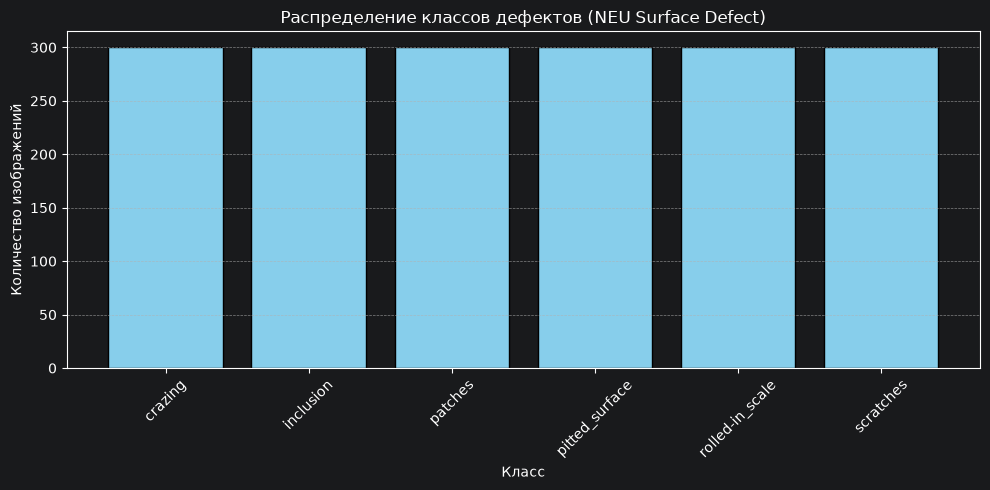


Всего проверено изображений: 30
Уникальные размеры: {(200, 200)}


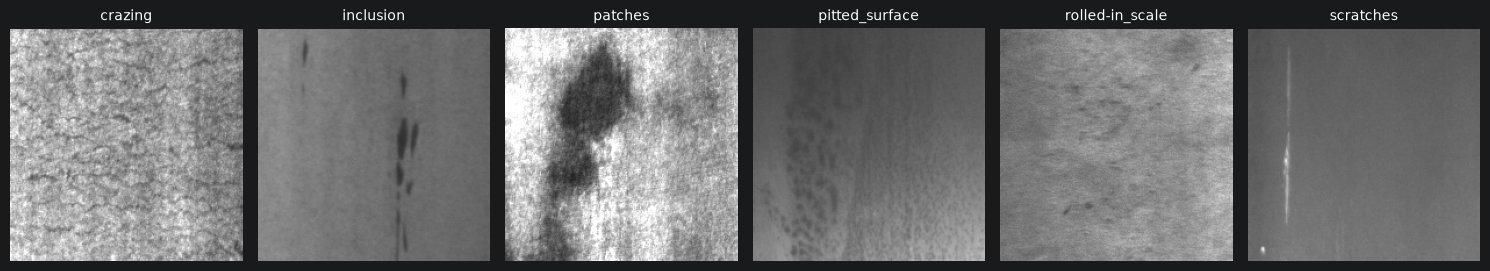

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

DATA_DIR = "../data/raw/NEU-DET-organized"

classes = sorted(os.listdir(DATA_DIR))
class_counts = {}
image_sizes = []

for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    if os.path.isdir(cls_path):
        files = os.listdir(cls_path)
        class_counts[cls] = len(files)

        for f in files[:5]:
            img_path = os.path.join(cls_path, f)
            try:
                with Image.open(img_path) as img:
                    image_sizes.append(img.size)
            except Exception as e:
                print(f"Ошибка чтения {img_path}: {e}")

plt.figure(figsize=(10, 5))
plt.bar(class_counts.keys(), class_counts.values(), color='skyblue', edgecolor='black')
plt.title("Распределение классов дефектов (NEU Surface Defect)")
plt.xlabel("Класс")
plt.ylabel("Количество изображений")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(f"\nВсего проверено изображений: {len(image_sizes)}")
print(f"Уникальные размеры: {set(image_sizes)}")

fig, axes = plt.subplots(1, len(classes), figsize=(15, 3))
for i, cls in enumerate(classes):
    cls_path = os.path.join(DATA_DIR, cls)
    img_file = os.listdir(cls_path)[0]
    img = Image.open(os.path.join(cls_path, img_file))
    axes[i].imshow(img)
    axes[i].set_title(cls, fontsize=10)
    axes[i].axis('off')
plt.tight_layout()
plt.show()